In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [2]:
# Load Dataset
df = pd.read_csv("/content/drive/MyDrive/AI-Project-5th-Sem/cleaned_football_dataset_final.csv")

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (50149, 44)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50149 entries, 0 to 50148
Data columns (total 44 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   country_of_citizenship                49880 non-null  object 
 1   date_of_birth                         50100 non-null  object 
 2   sub_position                          49563 non-null  object 
 3   position                              50149 non-null  object 
 4   foot                                  44256 non-null  object 
 5   height_in_cm                          45784 non-null  float64
 6   contract_expiration_date              31581 non-null  object 
 7   international_caps                    50149 non-null  int64  
 8   international_goals                   19356 non-null  float64
 9   current_club_domestic_competition_id  47163 non-null  object 
 10  current_club_name                     47163 non-null  object 
 11  market_value_in

In [5]:
# Convert the text placeholder "Missing" into an actual missing value
df["position"] = df["position"].replace("Missing", np.nan)

# Verify
print(df["position"].value_counts(dropna=False))
print("\nMissing values in position:", df["position"].isna().sum())

position
Defender      15961
Midfield      14272
Attack        13502
Goalkeeper     5828
NaN             586
Name: count, dtype: int64

Missing values in position: 586


In [6]:
target_score = "Player_Future_Potential_Score"
target_rating = "Player_Future_Potential_Rating"

print("Target score exists:", target_score in df.columns)
print("Target rating exists:", target_rating in df.columns)

Target score exists: True
Target rating exists: True


In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
object_cols = df.select_dtypes(include="object").columns.tolist()

date_cols = [
    col for col in [
        "date_of_birth",
        "contract_expiration_date"
    ]
    if col in df.columns
]

categorical_cols = [
    col for col in object_cols
    if col not in date_cols
    and col not in [target_rating]
]

print("Numerical columns:", len(numerical_cols))
print("Object columns:", len(object_cols))
print("Date columns:", len(date_cols))
print("Categorical/Text columns:", len(categorical_cols))

Numerical columns: 26
Object columns: 18
Date columns: 2
Categorical/Text columns: 15


In [8]:
exclude_from_pca = [
    target_score,
    target_rating,

    "player_id",
    "current_club_id",
    "current_national_team_id",
    "club_id",
    "competition_id",
    "country_id",

    "player_code",
    "filename",

    "image_url",
    "url",
    "url_x",
    "url_y",

    "date_of_birth",
    "contract_expiration_date"
]

exclude_from_pca = [
    col for col in exclude_from_pca
    if col in df.columns
]

In [9]:
X = df.drop(columns=exclude_from_pca).copy()

print("PCA candidate shape:", X.shape)
print("\nPCA candidate columns:")
print(X.columns.tolist())

PCA candidate shape: (50149, 40)

PCA candidate columns:
['country_of_citizenship', 'sub_position', 'position', 'foot', 'height_in_cm', 'international_caps', 'international_goals', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur', 'matches_played', 'total_minutes', 'avg_minutes', 'total_goals', 'avg_goals', 'total_assists', 'avg_assists', 'yellow_cards', 'red_cards', 'value_growth', 'transfer_count', 'total_transfer_fee', 'highest_transfer_fee', 'squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'national_team_players', 'stadium_name', 'stadium_seats', 'net_transfer_record', 'competition_code', 'name', 'sub_type', 'type', 'country_name', 'domestic_league_code', 'confederation', 'total_clubs']


In [10]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 25
['height_in_cm', 'international_caps', 'international_goals', 'market_value_in_eur', 'highest_market_value_in_eur', 'matches_played', 'total_minutes', 'avg_minutes', 'total_goals', 'avg_goals', 'total_assists', 'avg_assists', 'yellow_cards', 'red_cards', 'value_growth', 'transfer_count', 'total_transfer_fee', 'highest_transfer_fee', 'squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'national_team_players', 'stadium_seats', 'total_clubs']

Categorical features: 15
['country_of_citizenship', 'sub_position', 'position', 'foot', 'current_club_domestic_competition_id', 'current_club_name', 'stadium_name', 'net_transfer_record', 'competition_code', 'name', 'sub_type', 'type', 'country_name', 'domestic_league_code', 'confederation']


In [11]:
cardinality = (
    X[categorical_features]
    .nunique(dropna=True)
    .sort_values(ascending=False)
)

print("Categorical cardinality:")
display(cardinality.to_frame("Unique_Values"))

Categorical cardinality:


,Unique_Values
current_club_name,793
stadium_name,758
net_transfer_record,481
country_of_citizenship,202
current_club_domestic_competition_id,32
country_name,31
domestic_league_code,31
name,28
competition_code,28
sub_position,13


In [12]:
categorical_for_pca = [
    col for col in [
        "position",
        "sub_position",
        "foot",
        "competition_code",
        "confederation",
        "domestic_league_code"
    ]
    if col in X.columns
]

print("Categorical columns selected for One-Hot Encoding:")
print(categorical_for_pca)

Categorical columns selected for One-Hot Encoding:
['position', 'sub_position', 'foot', 'competition_code', 'confederation', 'domestic_league_code']


In [13]:
numeric_for_pca = [
    col for col in numeric_features
    if col not in [
        "international_goals",
        "transfer_count",
        "total_transfer_fee",
        "highest_transfer_fee"
    ]
]

print("Numerical features going into PCA:")
print(numeric_for_pca)

print("\nNumber of numerical PCA features:", len(numeric_for_pca))

Numerical features going into PCA:
['height_in_cm', 'international_caps', 'market_value_in_eur', 'highest_market_value_in_eur', 'matches_played', 'total_minutes', 'avg_minutes', 'total_goals', 'avg_goals', 'total_assists', 'avg_assists', 'yellow_cards', 'red_cards', 'value_growth', 'squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'national_team_players', 'stadium_seats', 'total_clubs']

Number of numerical PCA features: 21


In [14]:
numeric_missing = (X[numeric_for_pca].isnull().mean().mul(100).sort_values(ascending=False))
display(numeric_missing.to_frame("Missing_Percentage"))

,Missing_Percentage
matches_played,41.115476
avg_assists,41.115476
yellow_cards,41.115476
avg_goals,41.115476
avg_minutes,41.115476
red_cards,41.115476
foreigners_percentage,11.760952
average_age,9.523620
height_in_cm,8.704062
total_clubs,7.561467


In [15]:
numeric_pipeline = Pipeline(steps=[
    ("num_imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [16]:
categorical_pipeline = Pipeline(steps=[
        ("cat_imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [17]:
transformer = ColumnTransformer([
    ('num', numeric_pipeline, numeric_for_pca),
    ('cat', categorical_pipeline, categorical_for_pca)
])

In [18]:
transformed_data = transformer.fit_transform(X)

In [19]:
transformed_cols = transformer.get_feature_names_out()

In [20]:
transformed_data_df = pd.DataFrame(transformed_data, columns=transformed_cols)
display(transformed_data_df[:20])

,num__height_in_cm,num__international_caps,num__market_value_in_eur,num__highest_market_value_in_eur,num__matches_played,num__total_minutes,num__avg_minutes,num__total_goals,num__avg_goals,num__total_assists,...,cat__domestic_league_code_RO1,cat__domestic_league_code_RSK1,cat__domestic_league_code_RU1,cat__domestic_league_code_SA1,cat__domestic_league_code_SC1,cat__domestic_league_code_SE1,cat__domestic_league_code_SER1,cat__domestic_league_code_TR1,cat__domestic_league_code_TS1,cat__domestic_league_code_UKR1
0,0.282170,-0.230716,-0.020664,3.375228,1.258398,1.082047,0.291004,3.344976,3.628346,2.477321,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.127762,-0.230716,-0.069500,0.654472,1.490593,1.997193,1.553013,-0.304850,-0.513205,-0.369234,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000306,-0.230716,-0.020664,3.931746,1.055228,1.078152,0.671542,2.584595,3.141770,1.110974,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000306,-0.230716,-0.176939,2.695039,-0.657209,-0.573201,0.918523,-0.304850,-0.513205,-0.369234,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.691490,-0.230716,-0.196473,0.036118,-0.541112,-0.422689,1.612259,-0.304850,-0.513205,-0.369234,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.000306,-0.230716,-0.137870,0.839978,-0.120258,0.064871,1.476896,-0.228812,-0.227001,-0.141510,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,0.000306,-0.230716,0.077008,0.839978,-0.613672,-0.549836,0.093894,-0.304850,-0.513205,-0.255372,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,-0.422490,-0.230716,-0.147637,1.829344,0.402180,0.143339,-0.388882,0.379493,0.858347,0.086215,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,1.550558,-0.230716,-0.176939,-0.180306,-0.308917,-0.319199,0.130688,-0.228812,-0.299853,-0.255372,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,1.550558,-0.230716,-0.167172,1.149155,0.866570,0.542694,-0.199596,1.672139,2.285824,0.541663,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
# Apply PCA to all processed features

pca_full = PCA()
X_pca_full = pca_full.fit_transform(transformed_data)

print("Original processed features:", transformed_data.shape[1])
print("Total PCA components:", X_pca_full.shape[1])

Original processed features: 103
Total PCA components: 103


In [22]:
# Explained variance of each principal component

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

explained_variance_percent = explained_variance * 100
cumulative_variance_percent = cumulative_variance * 100

# Create a DataFrame for tabular output
pca_variance_table = pd.DataFrame({
    "PC": range(1, 15),
    "Individual Explained Variance (%)": np.round(explained_variance_percent[:14], 2),
    "Cumulative Explained Variance (%)": np.round(cumulative_variance_percent[:14], 2)
})

print("Explained Variance (First 15 Principal Components):")
display(pca_variance_table)

Explained Variance (First 15 Principal Components):


,PC,Individual Explained Variance (%),Cumulative Explained Variance (%)
0,1,25.70,25.70
1,2,10.06,35.76
2,3,6.76,42.52
3,4,6.39,48.91
4,5,5.31,54.22
5,6,4.20,58.43
6,7,3.85,62.28
7,8,3.41,65.69
8,9,3.28,68.97
9,10,3.22,72.19


In [23]:
# Number of components required to retain 80% and 90% variance

pcs_80 = np.argmax(cumulative_variance >= 0.80) + 1
pcs_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components required for >=80% variance:", pcs_80)
print("Components required for >=90% variance:", pcs_90)

print(f"\nVariance retained with {pcs_80} PCs: " f"{cumulative_variance[pcs_80 - 1] * 100:.2f}%")
print(f"Variance retained with {pcs_90} PCs: " f"{cumulative_variance[pcs_90 - 1] * 100:.2f}%")

Components required for >=80% variance: 13
Components required for >=90% variance: 22

Variance retained with 13 PCs: 80.35%
Variance retained with 22 PCs: 90.47%


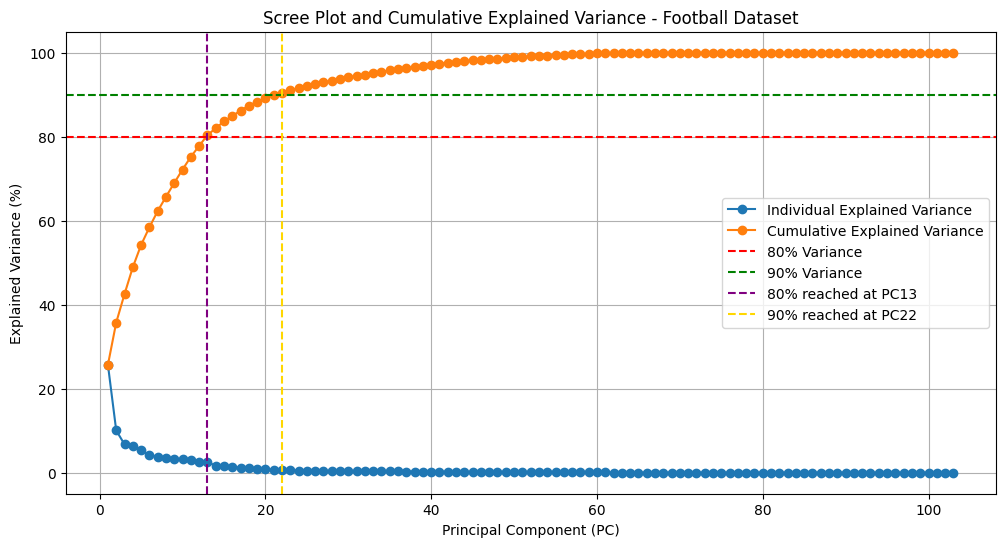

In [24]:
# Scree plot and cumulative explained variance

plt.figure(figsize=(12, 6))
components = np.arange(1, len(explained_variance) + 1)

plt.plot(components, explained_variance_percent, marker="o", label="Individual Explained Variance")
plt.plot(components, cumulative_variance_percent, marker="o", label="Cumulative Explained Variance")

plt.axhline(80, linestyle="--", label="80% Variance", color="red")
plt.axhline(90, linestyle="--", label="90% Variance", color="green")

plt.axvline(pcs_80, linestyle="--", label=f"80% reached at PC{pcs_80}", color="purple")
plt.axvline(pcs_90, linestyle="--", label=f"90% reached at PC{pcs_90}", color="gold")

plt.xlabel("Principal Component (PC)")
plt.ylabel("Explained Variance (%)")

plt.title("Scree Plot and Cumulative Explained Variance - Football Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# PCA transformation using the number of components
# required to retain at least 80% variance

pca_80 = PCA(n_components=pcs_80)
X_pca_80 = pca_80.fit_transform(transformed_data)

print("Original processed features:", transformed_data.shape[1])
print("Selected PCA components:", X_pca_80.shape[1])
print(f"Variance retained: " f"{pca_80.explained_variance_ratio_.sum() * 100:.2f}%")

Original processed features: 103
Selected PCA components: 13
Variance retained: 80.35%


In [26]:
# Create PCA loading matrix

pca_columns = [
    f"PC{i}"
    for i in range(1, pcs_80 + 1)
]

loadings = pd.DataFrame(
    pca_80.components_.T,
    index=transformed_cols,
    columns=pca_columns
)

display(loadings)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
num__height_in_cm,0.001349,0.050129,-0.239059,0.184381,0.394688,0.597189,-0.219231,-0.298952,0.053406,-0.010607,0.054540,0.397325,-0.118064
num__international_caps,0.188427,-0.026650,0.094872,-0.009307,0.069250,-0.078152,0.252256,-0.298149,-0.504211,0.481552,0.415178,0.131993,0.302159
num__market_value_in_eur,0.235937,0.097772,0.273518,-0.110414,0.427108,-0.005428,0.140338,0.176495,0.102585,-0.086191,-0.192563,0.018918,0.164946
num__highest_market_value_in_eur,0.332325,0.029363,0.221269,-0.073774,0.298939,-0.020897,0.105433,0.047148,0.056510,-0.042367,-0.110975,0.010139,-0.000845
num__matches_played,0.348715,-0.133926,-0.151855,0.129851,-0.093737,-0.081975,-0.000617,-0.067098,0.014866,-0.039611,0.025865,-0.035866,-0.199991
...,...,...,...,...,...,...,...,...,...,...,...,...,...
cat__domestic_league_code_SE1,-0.001910,-0.002222,-0.002743,-0.002394,0.003413,0.002227,0.003744,0.000283,-0.003340,-0.003747,-0.001174,0.000261,-0.001840
cat__domestic_league_code_SER1,-0.002455,-0.003017,-0.002358,-0.001359,0.002451,0.006611,0.012924,-0.005339,-0.013674,-0.020765,-0.004911,-0.000221,0.002271
cat__domestic_league_code_TR1,-0.006548,-0.023428,0.020785,0.011508,-0.006720,-0.012989,0.022179,-0.027644,-0.062010,0.027532,0.037951,0.001051,0.032050
cat__domestic_league_code_TS1,-0.001879,0.001544,-0.004513,-0.003087,0.001248,0.006506,0.011225,-0.001434,-0.005518,-0.003382,-0.005305,0.001222,-0.000141


In [27]:
# Display the strongest contributing features for each PC

for pc in pca_columns:

    print("\n" + "=" * 60)
    print(f"Strongest Features for {pc}")
    print("=" * 60)

    strongest = (loadings[pc].abs().sort_values(ascending=False).head(5))

    for feature in strongest.index:
        actual_value = loadings.loc[feature, pc]
        print(f"{feature}: {actual_value:.4f}")


Strongest Features for PC1
num__matches_played: 0.3487
num__total_minutes: 0.3399
num__value_growth: 0.3327
num__highest_market_value_in_eur: 0.3323
num__total_assists: 0.3269

Strongest Features for PC2
num__foreigners_number: 0.5188
num__national_team_players: 0.4705
num__foreigners_percentage: 0.4139
num__squad_size: 0.3124
num__stadium_seats: 0.2623

Strongest Features for PC3
num__total_clubs: 0.3686
num__foreigners_percentage: -0.3610
num__stadium_seats: 0.3080
num__foreigners_number: -0.2799
num__market_value_in_eur: 0.2735

Strongest Features for PC4
num__avg_minutes: 0.3715
num__avg_goals: -0.3492
num__total_clubs: 0.3339
num__avg_assists: -0.2816
num__average_age: 0.2747

Strongest Features for PC5
num__market_value_in_eur: 0.4271
num__height_in_cm: 0.3947
num__avg_assists: -0.2990
num__highest_market_value_in_eur: 0.2989
num__value_growth: 0.2983

Strongest Features for PC6
num__height_in_cm: 0.5972
num__avg_goals: 0.4365
num__avg_minutes: 0.2700
num__squad_size: 0.2670
num

In [28]:
# Create dataframe containing PCA components

pca_df = pd.DataFrame(X_pca_80, columns=pca_columns, index=df.index)
print("PCA dataset shape:", pca_df.shape)
display(pca_df.head())

PCA dataset shape: (50149, 13)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,6.804990,0.973146,2.075537,-1.857473,-1.317520,2.524496,-2.138979,0.452023,1.055951,0.246215,0.227234,-0.698903,-0.640720
1,2.859701,1.763688,-1.445026,3.310808,0.630615,-0.447146,-1.922496,0.075340,1.385951,-1.197894,1.563716,-0.204700,2.064296
2,6.054608,0.333766,0.466934,-1.823627,-0.095410,2.068239,0.353285,0.167208,1.907722,0.049450,-0.859475,-1.002494,1.182017
3,1.632319,3.427659,1.073349,0.689143,1.778808,-0.004285,0.022627,1.069360,0.532883,0.564497,-0.261075,-0.566953,0.006032
4,0.093564,3.174980,0.244992,2.111700,0.955621,1.528390,-1.559700,0.714033,0.287239,-0.398508,2.232127,-0.641398,-0.077630


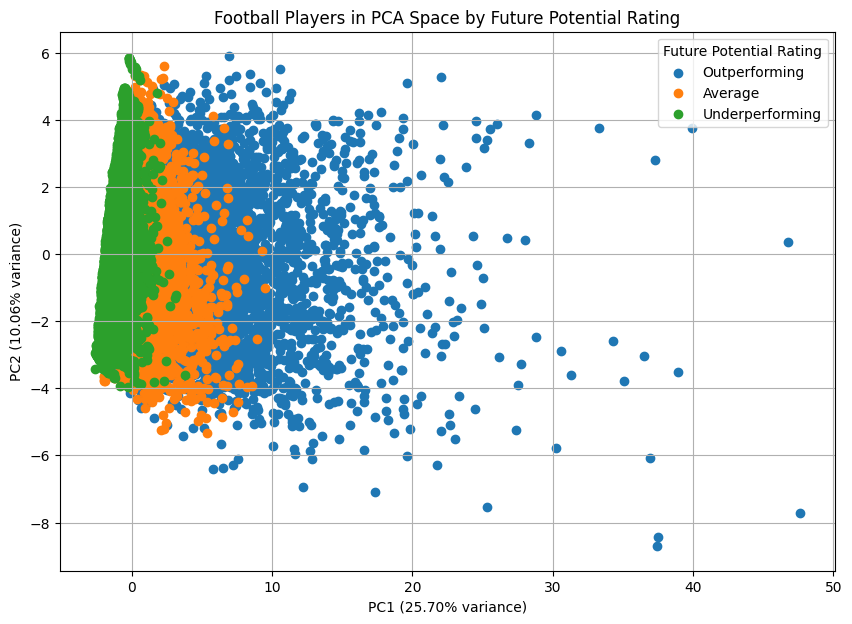

In [29]:
# PC1 vs PC2 VISUALIZATION BY FUTURE POTENTIAL RATING

pca_plot_df = pca_df[["PC1", "PC2"]].copy()

pca_plot_df["Player_Future_Potential_Rating"] = (
    df[target_rating].values
)

plt.figure(figsize=(10, 7))

for rating in pca_plot_df[
    "Player_Future_Potential_Rating"
].dropna().unique():

    mask = (
        pca_plot_df[
            "Player_Future_Potential_Rating"
        ] == rating
    )

    plt.scatter(
        pca_plot_df.loc[mask, "PC1"],
        pca_plot_df.loc[mask, "PC2"],
        label=rating
    )

plt.xlabel(
    f"PC1 ({pca_80.explained_variance_ratio_[0] * 100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca_80.explained_variance_ratio_[1] * 100:.2f}% variance)"
)

plt.title(
    "Football Players in PCA Space by Future Potential Rating"
)

plt.legend(title="Future Potential Rating")
plt.grid(True)
plt.show()

In [30]:
print(df[target_rating].value_counts(dropna=False))

Player_Future_Potential_Rating
Average            25872
Underperforming    16508
Outperforming       7769
Name: count, dtype: int64


In [31]:
# Create a DataFrame for explained variance summary
pca_summary = pd.DataFrame({
    "PC": components,
    "Explained_Variance_Percent": explained_variance_percent,
    "Cumulative_Variance_Percent": cumulative_variance_percent
})

# Save explained variance
pca_summary.to_csv(
    "football_pca_explained_variance.csv",
    index=False
)

# Save PCA loading matrix
loadings.to_csv(
    "football_pca_loadings.csv"
)

# Save PCA dataset
pca_df.to_csv(
    "football_pca_13_components.csv",
    index=False
)

# Save PC1-PC2 visualization data
pca_plot_df.to_csv(
    "football_pca_pc1_pc2_analysis.csv",
    index=False
)

print("PCA analysis outputs saved successfully.")

PCA analysis outputs saved successfully.


In [32]:
# FINAL PCA SUMMARY

print("=" * 70)
print("FINAL PCA SUMMARY - FOOTBALL PLAYER DATASET")
print("=" * 70)

print("Original dataset shape:", df.shape)

print(
    "Numerical features used for PCA:",
    len(numeric_for_pca)
)

print(
    "Categorical features encoded:",
    len(categorical_for_pca)
)

print(
    "Total processed features:",
    transformed_data.shape[1]
)

print(
    "Selected PCA components:",
    pcs_80
)

print(
    f"Variance retained by selected components: "
    f"{pca_80.explained_variance_ratio_.sum() * 100:.2f}%"
)

print(
    "Components required for >=90% variance:",
    pcs_90
)

print(
    f"Variance retained at 90% threshold: "
    f"{cumulative_variance[pcs_90 - 1] * 100:.2f}%"
)

print(
    f"Dimensionality reduction: "
    f"{((transformed_data.shape[1] - pcs_80) / transformed_data.shape[1]) * 100:.2f}%"
)

print("\nPCA coding and analysis completed successfully.")

FINAL PCA SUMMARY - FOOTBALL PLAYER DATASET
Original dataset shape: (50149, 44)
Numerical features used for PCA: 21
Categorical features encoded: 6
Total processed features: 103
Selected PCA components: 13
Variance retained by selected components: 80.35%
Components required for >=90% variance: 22
Variance retained at 90% threshold: 90.47%
Dimensionality reduction: 87.38%

PCA coding and analysis completed successfully.
